In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import math
import multiprocessing
from scipy.ndimage import map_coordinates

# pyfftw is faster but optional (e.g. not installed by default on Colab):
# fall back to numpy's FFT if it is missing
try:
    import pyfftw
    from pyfftw.interfaces.numpy_fft import fft2, ifft2

    pyfftw.interfaces.cache.enable()
    pyfftw.config.NUM_THREADS = multiprocessing.cpu_count()
except ImportError:
    from numpy.fft import fft2, ifft2
    print("pyfftw not found, using numpy.fft (slower). Optional: pip install pyfftw")

class SamplingOperator:

    def __init__(self, n_prop, dx_prop, n_det, dx_det, shift_x=0.0, shift_y=0.0, rotation_deg=0.0, origin=None):
        """
        Maps propagated field on propagation grid
        to detector field on detector grid.

        n_prop : propagation grid size
        dx_prop : propagation grid pitch

        n_det : detector grid size
        dx_det : detector pixel pitch

        shift_x, shift_y : physical displacement of the detector centre
                           from the optical axis [m]
        rotation_deg : rotation of the detector about its centre,
                       counter-clockwise from x towards y [deg]
        origin : propagation-grid index of the optical axis
                 (default n_prop/2, use Propagator.origin)
        """

        self.n_prop = n_prop
        self.n_det = n_det

        # [FIX 1] the optical axis is not necessarily at n_prop/2 once the
        # SLM is embedded in a larger (zero-padded) propagation grid
        if origin is None:
            origin = n_prop / 2

        theta = np.deg2rad(rotation_deg)

        # detector coordinates (physical)
        x_det = (np.arange(n_det) - n_det/2) * dx_det
        y_det = (np.arange(n_det) - n_det/2) * dx_det

        Xd, Yd = np.meshgrid(x_det, y_det, indexing="ij")

        # [FIX 3] forward transform: detector pixel at local (Xd, Yd)
        # sits at R(theta) (Xd, Yd) + shift in the propagation plane
        ct = np.cos(theta)
        st = np.sin(theta)

        Xp = ct*Xd - st*Yd + shift_x
        Yp = st*Xd + ct*Yd + shift_y

        # convert physical coordinates
        # to propagation-grid indices

        Ix = Xp/dx_prop + origin
        Iy = Yp/dx_prop + origin

        x0 = np.floor(Ix).astype(np.int64)
        y0 = np.floor(Iy).astype(np.int64)

        x1 = x0 + 1
        y1 = y0 + 1

        # Valid interpolation region
        valid = ((x0 >= 0) & (x1 < n_prop) & (y0 >= 0) & (y1 < n_prop))

        # [FIX 1] pixels outside the grid read 0, which a real camera would not
        n_outside = np.count_nonzero(~valid)
        if n_outside > 0:
            print(f"WARNING: {n_outside} of {n_det**2} detector pixels lie outside "
                  f"the propagation grid and will read 0. Increase n_prop.")

        x0 = np.clip(x0, 0, n_prop - 1)
        x1 = np.clip(x1, 0, n_prop - 1)

        y0 = np.clip(y0, 0, n_prop - 1)
        y1 = np.clip(y1, 0, n_prop - 1)

        ax = Ix - np.floor(Ix)
        ay = Iy - np.floor(Iy)

        w00 = (1 - ax) * (1 - ay)
        w01 = (1 - ax) * ay
        w10 = ax * (1 - ay)
        w11 = ax * ay

        w00 *= valid
        w01 *= valid
        w10 *= valid
        w11 *= valid

        self.x0 = x0
        self.x1 = x1

        self.y0 = y0
        self.y1 = y1

        self.w00 = w00
        self.w01 = w01
        self.w10 = w10
        self.w11 = w11

    def forward(self, U):
        """
        U shape:
            (L, n_prop, n_prop)

        returns:
            (L, n_det, n_det)
        """

        return (self.w00[None] * U[:, self.x0, self.y0]
            + self.w01[None] * U[:, self.x0, self.y1]
            + self.w10[None] * U[:, self.x1, self.y0]
            + self.w11[None] * U[:, self.x1, self.y1])

    def adjoint(self, V):
        """
        V shape:
            (L, n_det, n_det)

        returns:
            (L, n_prop, n_prop)
        """

        L = V.shape[0]

        out = np.zeros((L, self.n_prop, self.n_prop), dtype=V.dtype)

        for l in range(L):
            np.add.at(out[l], (self.x0, self.y0), self.w00 * V[l])
            np.add.at(out[l], (self.x0, self.y1), self.w01 * V[l])
            np.add.at(out[l], (self.x1, self.y0), self.w10 * V[l])
            np.add.at(out[l], (self.x1, self.y1), self.w11 * V[l])

        return out

class Propagator:

    def __init__(self, n_in, n, dx, wavelength, z):
        """
        n_in : SLM grid size (the field is defined on n_in x n_in)
        n : propagation grid size, n >= n_in (the SLM is zero-padded to n x n)
        """

        # [FIX 1] the SLM field is embedded in a larger zero-padded grid so
        # light leaving the SLM aperture does not wrap around onto the camera
        self.n_in = n_in
        self.n = n
        self.dx = dx
        self.wavelength = wavelength
        self.z = z

        self.offset = (n - n_in) // 2
        # grid index of the optical axis (SLM pixel i is at (i - n_in/2) * dx)
        self.origin = self.offset + n_in / 2

        fx = np.fft.fftfreq(n, d=dx)
        fy = np.fft.fftfreq(n, d=dx)
        FX, FY = np.meshgrid(fx, fy)

        term = (1 - (wavelength * FX) ** 2 - (wavelength * FY) ** 2)
        k = 2 * np.pi / wavelength

        # [FIX 1] band-limited angular spectrum (Matsushima & Shimobaba 2009):
        # drop frequencies where the transfer-function phase is undersampled
        df = 1 / (n * dx)
        f_limit = 1 / (wavelength * np.sqrt((2 * df * z) ** 2 + 1))
        band = (np.abs(FX) <= f_limit) & (np.abs(FY) <= f_limit)

        self.H = np.exp(1j * k * z * np.sqrt(term.astype(complex))) * band
        self.H_adj = np.conj(self.H)

    def pad(self, U):

        out = np.zeros(U.shape[:-2] + (self.n, self.n), dtype=complex)
        out[..., self.offset:self.offset + self.n_in, self.offset:self.offset + self.n_in] = U

        return out

    def crop(self, V):

        return V[..., self.offset:self.offset + self.n_in, self.offset:self.offset + self.n_in]

    def forward(self, U):
        '''(L, n_in, n_in) on the SLM -> (L, n, n) on the propagation grid'''

        A = fft2(self.pad(U), axes=(-2,-1), norm="ortho")

        return ifft2(A * self.H[None,:,:], axes=(-2,-1), norm="ortho")

    def adjoint(self, V):
        '''(L, n, n) on the propagation grid -> (L, n_in, n_in) on the SLM'''

        A = fft2(V, axes=(-2,-1), norm="ortho")

        return self.crop(ifft2(A * self.H_adj[None,:,:], axes=(-2,-1), norm="ortho"))

def choose_prop_grid(n_slm, dx_slm, n_det, dx_det, wavelength, z, shift_max=0.0, rotation_max_deg=0.0, margin=2.0):
    '''[FIX 1] Smallest power-of-two propagation grid that
       - contains the SLM and the (shifted, rotated) detector,
       - is wide enough that light diffracted off the SLM edge cannot
         wrap around (FFT periodicity) and land on the detector,
       - samples the angular-spectrum transfer function: n >= wavelength z / dx^2'''

    slm_half = n_slm * dx_slm / 2

    theta = np.deg2rad(rotation_max_deg)
    det_half = n_det * dx_det / 2 * (abs(np.cos(theta)) + abs(np.sin(theta))) + shift_max

    # largest transverse displacement of light diffracted by the SLM grid
    s = wavelength / (2 * dx_slm)
    spread = z * s / np.sqrt(1 - s ** 2)

    width = margin * max(slm_half + spread + det_half, 2 * det_half, 2 * slm_half)
    n_min = max(width / dx_slm, wavelength * z / dx_slm ** 2)

    return int(2 ** np.ceil(np.log2(n_min)))

def define_sample(n, sigma, dx_slm):
    '''Define the sample amplitude and phase profile'''

    x = (np.arange(n) - n/2) * dx_slm
    y = (np.arange(n) - n/2) * dx_slm

    X, Y = np.meshgrid(x, y, indexing="ij")

    amplitude = np.exp(-(X ** 2 + Y ** 2) / (2 * sigma ** 2))
    phase = (2 * np.pi * (X**2 + Y**2) / (sigma ** 2))

    return amplitude * np.exp(1j * phase)

def define_masks(L, n, rng):
    '''Define the masks'''

    # [FIX 5] random numbers come from a seeded generator
    i = rng.integers(0, 256, size=(L, n, n))
    phi = 2*np.pi * i / 256

    return np.exp(1j * phi)

def y_i(D, X, propagator, sampler):
    '''Simulates a measurement'''

    inner = sampler.forward(forward(X, np.conj(D), propagator))

    return np.abs(inner)**2

def forward(X, D_conj, propagator):
    '''Propagates the wave X forward from the mask plane to the detector plane to form Y'''
    '''Y_l = A(X) = P(D_l^* X)'''
    '''D_l is the mask, P is forward propagation'''
    '''X has shape (n, n)'''

    U = D_conj * X[None, :, :]
    return propagator.forward(U)


def adjoint(Y, D, propagator):
    '''Propagates the wave Y backward from the detector plane to the mask plane to form X'''
    '''X = A^*(Y) = Σ_l D_l P^*(Y_l)'''
    '''D_l is the mask, P^* is back propagation'''
    '''Y has shape (L, n, n)'''

    B = propagator.adjoint(Y)
    return np.sum(D * B, axis=0)


def add_noise(y, photons_per_pixel, snr_db, rng):
    '''Adds noise to the measurement y'''

    y = y / np.mean(y)
    counts = rng.poisson(y * photons_per_pixel)
    y_noisy = counts / photons_per_pixel
    signal_power = np.mean(y_noisy)
    noise_power = signal_power / (10**(snr_db/10))
    sigma = np.sqrt(noise_power)
    y_noisy += rng.normal(0, sigma, y.shape)

    return np.maximum(y_noisy, 0)

def spectral_init(y, D, propagator, sampler, iter, tol, rng):
    '''Computes the dominant eigenvector of A_l^* diag(y_l) A_l'''

    n = D.shape[1]

    z = (rng.standard_normal((n, n)) + 1j * rng.standard_normal((n, n)))
    z /= np.linalg.norm(z)

    D_conj = np.conj(D)

    for _ in range(iter):
        Az = sampler.forward(forward(z, D_conj, propagator))
        weighted = sampler.adjoint(y * Az)
        w = adjoint(weighted, D, propagator)

        z_new = w / np.linalg.norm(w)
        corr = np.abs(np.vdot(z_new, z))

        if 1.0 - corr < tol:
            z = z_new
            break

        z = z_new

    return z

def Wirtinger_iteration(x0, y, D, propagator, sampler, iter, tol, tau0, mu_max):
    '''Solves the minimzation f(X) = Σ_l(|A_l(X)|^2 - y_l)^2 using Wirtinger Flow '''

    x = x0.copy()
    L = D.shape[0]
    D_conj = np.conj(D)

    for tau in range(iter):
        mu = min(1 - np.exp(-tau/tau0), mu_max)

        inner = sampler.forward(forward(x, D_conj, propagator))

        residual = np.abs(inner) ** 2 - y
        g = adjoint(sampler.adjoint(residual * inner), D, propagator) / L

        x -= mu * g

        grad_norm = np.sqrt(np.real(np.vdot(g, g)))
        x_norm = np.sqrt(np.real(np.vdot(x, x)))

        if grad_norm / x_norm < tol:
            break

    return x

def generate_measurement(x, propagator, sampler, photon_count, snr_db, L, n, rng):
    ''''Generate the masks D and the measurements y_i'''

    start = time.perf_counter()
    D = define_masks(L, n, rng)
    y = y_i(D, x, propagator, sampler)
    #y = add_noise(y, photon_count, snr_db, rng)
    end = time.perf_counter()

    print(f"Ran in {end - start}s")

    return y, D

def reconstruct_x(y, D, propagator, sampler, iter_WF, iter_SI, tol_WF, tol_SI, tau0, mu_max, plot_x, sigma, dx_slm, rng):
    '''Reconstruct the object x given y, D and H'''

    start = time.perf_counter()

    start_spec = time.perf_counter()
    x0 = spectral_init(y, D, propagator, sampler, iter_SI, tol_SI, rng)
    end_spec = time.perf_counter()

    start_Wirt = time.perf_counter()
    x_r = Wirtinger_iteration(x0, y, D, propagator, sampler, iter_WF, tol_WF, tau0, mu_max)
    end_Wirt = time.perf_counter()

    end = time.perf_counter()

    runtime = end - start
    runtime_init = end_spec - start_spec
    runtime_Wirt = end_Wirt - start_Wirt

    if (plot_x == True):
        plot2D(x, x_r, dx_slm)

    return x_r, [runtime, runtime_init, runtime_Wirt]

def plot2D(X_true, X_rec, dx):
    """Generate 2D plot of the true object and reconstructed object
       with axes in physical units."""

    # [FIX 2] angle(<X_rec, X_true>) is the phase X_rec must be rotated BY
    # to match X_true, so multiply by exp(+i theta)
    theta = np.angle(np.vdot(X_rec.ravel(), X_true.ravel()))
    X_rec = X_rec * np.exp(1j * theta)
    X_rec = X_rec * (np.max(np.abs(X_true)) / (np.max(np.abs(X_rec)) + 1e-12))

    amp_true = np.abs(X_true)
    amp_rec = np.abs(X_rec)

    phase_true = np.angle(X_true)
    phase_rec = np.angle(X_rec)

    #amp_vmin = min(amp_true.min(), amp_rec.min())
    amp_vmin = 0
    amp_vmax = max(amp_true.max(), amp_rec.max())

    n = X_true.shape[0]
    L = n * dx

    # Plot in mm
    extent = [-L/2 * 1e3, L/2 * 1e3, -L/2 * 1e3, L/2 * 1e3]

    fig, ax = plt.subplots(2, 2, figsize=(6, 6), constrained_layout=True)

    im1 = ax[0,0].imshow(amp_true, cmap="viridis", vmin=amp_vmin, vmax=amp_vmax, extent=extent, origin="lower")
    ax[0,0].set_title("True Amplitude")

    im2 = ax[0,1].imshow(amp_rec, cmap="viridis", vmin=amp_vmin, vmax=amp_vmax, extent=extent, origin="lower")
    ax[0,1].set_title("Recovered Amplitude")

    im3 = ax[1,0].imshow(phase_true, cmap="twilight", vmin=-np.pi, vmax=np.pi, extent=extent, origin="lower")
    ax[1,0].set_title("True Phase")

    im4 = ax[1,1].imshow(phase_rec, cmap="twilight", vmin=-np.pi, vmax=np.pi, extent=extent, origin="lower")
    ax[1,1].set_title("Recovered Phase")

    for a in ax.ravel():
        a.set_xlabel("x [mm]")
        a.set_ylabel("y [mm]")

    fig.colorbar(im1, ax=ax[0,:], shrink=0.8, label="Amplitude")
    fig.colorbar(im3, ax=ax[1,:], shrink=0.8, label="Phase [rad]")

    plt.show()

pyfftw not found, using numpy.fft (slower). Optional: pip install pyfftw


In [2]:
#Resolution and masks
n_slm = 45
dx_slm = 36e-6
L = 8

n_cam = 80
dx_cam = 24e-6

#Random seed (masks, noise and spectral initialisation are reproducible)
seed = 0

#Iteration and convergence parameters
iter_WF = 1000
iter_SI = 500
tol_WF = 1e-4
tol_SI = 1e-3
tau0 = 20
mu_max = 0.2

#Laser
wavelength = 631.8e-9
sigma = 1e-3

#Propagation
z = 0.2

#True system (generates the data). Change these to model errors (wavelength, z, shift, rotation)
wavelength_true = wavelength
z_true = z
shift_x_true = 0.0
shift_y_true = 0.0
rotation_true = 0.0

#Propagation grid: zero-padded around the SLM, sized for the larger of the true/ideal systems
n_prop = choose_prop_grid(n_slm, dx_slm, n_cam, dx_cam, max(wavelength, wavelength_true), max(z, z_true),
                          shift_max=max(abs(shift_x_true), abs(shift_y_true)), rotation_max_deg=abs(rotation_true))
print(f"SLM {n_slm*dx_slm*1e3:.2f} mm, camera {n_cam*dx_cam*1e3:.2f} mm, "
      f"propagation grid {n_prop} x {n_prop} ({n_prop*dx_slm*1e3:.2f} mm)")

prop = Propagator(n_slm, n_prop, dx_slm, wavelength_true, z_true)
prop_ideal = Propagator(n_slm, n_prop, dx_slm, wavelength, z)
sampler = SamplingOperator(n_prop=n_prop, dx_prop=dx_slm, n_det=n_cam, dx_det=dx_cam, shift_x=shift_x_true, shift_y=shift_y_true, rotation_deg=rotation_true, origin=prop.origin)
sampler_ideal = SamplingOperator(n_prop=n_prop, dx_prop=dx_slm, n_det=n_cam, dx_det=dx_cam, shift_x=0.0, shift_y=0.0, rotation_deg=0, origin=prop_ideal.origin)

#Noise parameters
photon_count = 1000
snr_db = 30

SLM 1.62 mm, camera 1.92 mm, propagation grid 256 x 256 (9.22 mm)


In [3]:
x = define_sample(n_slm, sigma, dx_slm)

In [4]:
y, D = generate_measurement(x, prop, sampler, photon_count, snr_db, L, n_slm, np.random.default_rng(seed))

Ran in 0.22517763899998045s


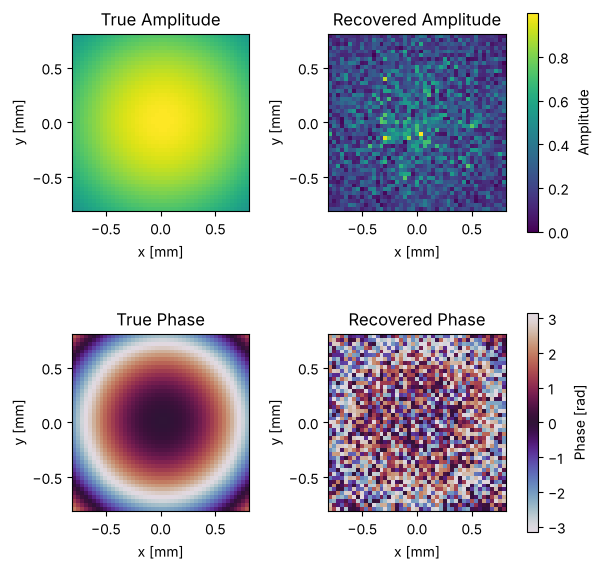

Total Runtime   (s): 79.53749868199998
Avg. Runtime    (s): 79.53749868199998
Avg. Runtime SI (s): 1.0365842319999956
Avg. Runtime W  (s): 78.50091241700002
Accuracy        (%): 0.3473366130541103


In [5]:
for j in range(1):
    runtime = 0
    runtime_spec = 0
    runtime_Wirt = 0
    accuracy = 0
    runs = 1
    norm_x = np.sqrt(np.real(np.vdot(x, x)))

    for i in range(runs):
        rng_init = np.random.default_rng(seed + 1 + i)
        X = reconstruct_x(y, D, prop_ideal, sampler_ideal, iter_WF, iter_SI, tol_WF, tol_SI, tau0, mu_max, True, sigma, dx_slm, rng_init)
        runtime += X[1][0]
        runtime_spec += X[1][1]
        runtime_Wirt += X[1][2]
        accuracy += np.abs(np.vdot(X[0], x)) / (np.sqrt(np.real(np.vdot(X[0], X[0]))) * norm_x)

    print(f"Total Runtime   (s): {runtime}")
    print(f"Avg. Runtime    (s): {runtime / runs}")
    print(f"Avg. Runtime SI (s): {runtime_spec / runs}")
    print(f"Avg. Runtime W  (s): {runtime_Wirt / runs}")
    print(f"Accuracy        (%): {accuracy / runs}")

In [6]:
from matplotlib.patches import Polygon

def visualize_sampling_2d(
    n_prop,
    dx_prop,
    n_det,
    dx_det,
    shift_x=0,
    shift_y=0,
    rotation_deg=0,
    step=16,
    origin=None,
    n_slm=None,
):
    """
    Visualize detector sample locations relative
    to the propagation grid.

    Uses the same convention as SamplingOperator: the detector pixel at
    local (Xd, Yd) sits at R(rotation) (Xd, Yd) + shift.
    """

    if origin is None:
        origin = n_prop / 2

    # Propagation grid boundary (the optical axis is at grid index `origin`)
    x_min_prop = -origin * dx_prop
    width_prop = n_prop * dx_prop

    # Detector coordinates
    x_det = (np.arange(n_det) - n_det/2) * dx_det
    y_det = (np.arange(n_det) - n_det/2) * dx_det

    Xd, Yd = np.meshgrid(
        x_det,
        y_det,
        indexing="ij"
    )

    theta = np.deg2rad(rotation_deg)

    ct = np.cos(theta)
    st = np.sin(theta)

    Xd_rot = ct * Xd - st * Yd + shift_x
    Yd_rot = st * Xd + ct * Yd + shift_y

    plt.figure(figsize=(8, 8))

    # Propagation window
    plt.gca().add_patch(
        plt.Rectangle(
            (x_min_prop, x_min_prop),
            width_prop,
            width_prop,
            fill=False,
            linewidth=3,
            color="blue",
            label="Propagation grid"
        )
    )

    # SLM aperture
    if n_slm is not None:
        width_slm = n_slm * dx_prop
        plt.gca().add_patch(
            plt.Rectangle(
                (-width_slm/2, -width_slm/2),
                width_slm,
                width_slm,
                fill=False,
                linewidth=2,
                color="green",
                label="SLM aperture",
                zorder=3
            )
        )

    plt.scatter(
        Xd_rot[::step, ::step],
        Yd_rot[::step, ::step],
        s=8,
        color="red",
        label="Detector pixels"
    )

    plt.axis("equal")
    plt.grid(True)

    plt.xlabel("x [m]")
    plt.ylabel("y [m]")

    plt.legend()

    plt.title(
        f"dx_prop={dx_prop:.2e}, "
        f"dx_det={dx_det:.2e}"
    )

    plt.show()

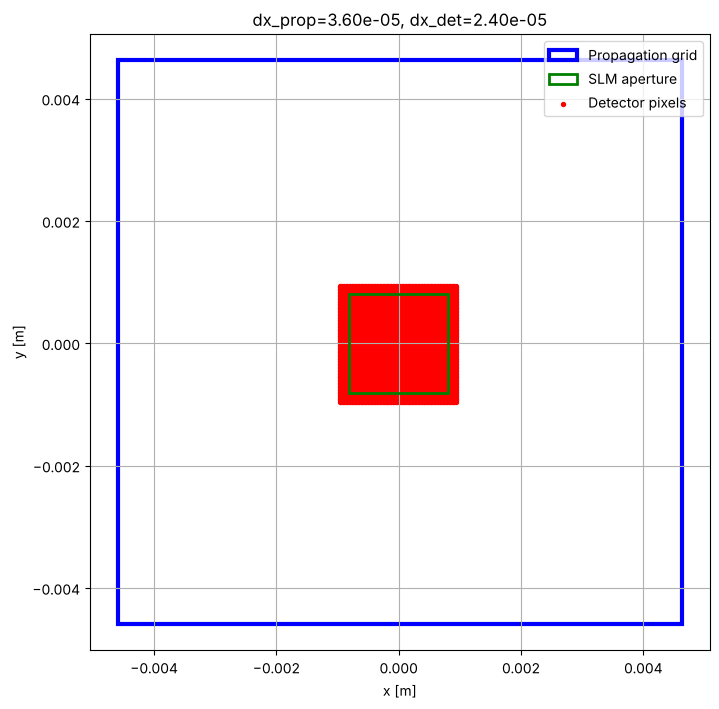

In [7]:
visualize_sampling_2d(
    n_prop=n_prop,
    dx_prop=dx_slm,
    n_det=n_cam,
    dx_det=dx_cam,
    shift_x=shift_x_true,
    shift_y=shift_y_true,
    rotation_deg=rotation_true,
    step = 1,
    origin=prop.origin,
    n_slm=n_slm
)